In [11]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [ ]:
ROOT = Path.cwd().parent

LMU = ROOT / "data" / "PKG-AML-Cytomorphology_LMU"

ANNOTATIONS_FILE = LMU / "annotations.dat"
SUMS_FILE = LMU / "AML-Cytomorphology.sums"

In [13]:
df_pkg_annotation = pd.read_csv( ANNOTATIONS_FILE,sep=" ", header=None,
    names=["relative_path", "class_code", "re-annotation", "re-re-annotation"]
)
display(df_pkg_annotation.head(), df_pkg_annotation.shape)

,relative_path,class_code,re-annotation,re-re-annotation
0,BAS/BAS_0001.tiff,BAS,NaN,NaN
1,BAS/BAS_0002.tiff,BAS,NaN,NaN
2,BAS/BAS_0003.tiff,BAS,NaN,NaN
3,BAS/BAS_0004.tiff,BAS,NaN,NaN
4,BAS/BAS_0005.tiff,BAS,NaN,NaN


(18365, 4)

In [14]:
df_pkg_sums = pd.read_csv( SUMS_FILE, sep=" ", header=None,
    names=["md5", "relative_path"]
)
display(df_pkg_sums.head(), df_pkg_sums.shape)

,md5,relative_path
0,53682b4f8395a8100ba4c8950a6a72a3,BAS/BAS_0037.tiff
1,4203b5d6293a9d004ac287b5ab80ae3c,MON/MON_0444.tiff
2,ef9bcafba54de97bf0ed79899fad6e65,NGS/NGS_4109.tiff
3,de6f1695dac341260f0234d804a62a82,LYT/LYT_1627.tiff
4,29872a296c868c41fd8595f01a619349,MYO/MYO_1473.tiff


(18365, 2)

In [15]:
df_pkg_info = df_pkg_annotation.merge(df_pkg_sums, on="relative_path", how="left")
display(df_pkg_info.head(), df_pkg_info.shape)

,relative_path,class_code,re-annotation,re-re-annotation,md5
0,BAS/BAS_0001.tiff,BAS,NaN,NaN,5fd5158b9f3a16fea899fecc544567ab
1,BAS/BAS_0002.tiff,BAS,NaN,NaN,c7cc2d8f8d63729f29dad75e80ffe05e
2,BAS/BAS_0003.tiff,BAS,NaN,NaN,f38de08e797e429f5a0860bbe49024f2
3,BAS/BAS_0004.tiff,BAS,NaN,NaN,8dc918143e7a97eafa30d7bdaed88656
4,BAS/BAS_0005.tiff,BAS,NaN,NaN,c148401ec9ad6d2fdad7f829375840a9


(18365, 5)

In [20]:
import hashlib
from tqdm import tqdm
import time

def compute_md5(path):
    hash_md5 = hashlib.md5()
    with open(path, "rb") as f: # lecture en binaire des images
        for chunk in iter(lambda: f.read(2**16), b""): 
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

md5_valid = []
widths = []
heights = []
channels = []
file_types = []
file_sizes = []
start = time.perf_counter()

for _, row in tqdm(df_pkg_info.iterrows()):

    img_path = LMU / row["relative_path"]

    # MD5
    current_md5 = compute_md5(img_path)
    md5_valid.append(current_md5 == row["md5"])

    # Image inforamtions 
    img = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)
    widths.append(img.shape[0])
    heights.append(img.shape[1])
    channels.append(1 if len(img.shape) == 2 else img.shape[2])

    # Fichier information
    file_types.append(img_path.suffix.lower())
    file_sizes.append(img_path.stat().st_size)

df_pkg_info["md5_valid"] = md5_valid
df_pkg_info["width"] = widths
df_pkg_info["height"] = heights
df_pkg_info["channels"] = channels
df_pkg_info["file_type"] = file_types
df_pkg_info["file_size"] = file_sizes
print(f"Temps : {time.perf_counter() - start:.1f} s")

Temps : 37.8 s


In [21]:
df_pkg_info = df_pkg_info.drop('md5', axis=1)
display(df_pkg_info.head())
display(df_pkg_info["md5_valid"].unique())
df_pkg_info.info()

,relative_path,class_code,re-annotation,re-re-annotation,md5_valid,width,height,channels,file_type,file_size
0,BAS/BAS_0001.tiff,BAS,NaN,NaN,True,400,400,4,.tiff,640154
1,BAS/BAS_0002.tiff,BAS,NaN,NaN,True,400,400,4,.tiff,640154
2,BAS/BAS_0003.tiff,BAS,NaN,NaN,True,400,400,4,.tiff,640154
3,BAS/BAS_0004.tiff,BAS,NaN,NaN,True,400,400,4,.tiff,640154
4,BAS/BAS_0005.tiff,BAS,NaN,NaN,True,400,400,4,.tiff,640154


array([ True])

<class 'pandas.DataFrame'>
RangeIndex: 18365 entries, 0 to 18364
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   relative_path     18365 non-null  str  
 1   class_code        18365 non-null  str  
 2   re-annotation     1905 non-null   str  
 3   re-re-annotation  1905 non-null   str  
 4   md5_valid         18365 non-null  bool 
 5   width             18365 non-null  int64
 6   height            18365 non-null  int64
 7   channels          18365 non-null  int64
 8   file_type         18365 non-null  str  
 9   file_size         18365 non-null  int64
dtypes: bool(1), int64(4), str(5)
memory usage: 1.3 MB


In [22]:
df_pkg_info = df_pkg_info.drop('md5_valid', axis=1) # elles sont toute valides


In [23]:
CLASS_MAPPING = {
    "BAS": "Basophil",
    "EBO": "Erythroblast",
    "EOS": "Eosinophil",
    "KSC": "Smudge cell",
    "LYA": "Lymphocyte (atypical)",
    "LYT": "Lymphocyte (typical)",
    "MMZ": "Metamyelocyte",
    "MOB": "Monoblast",
    "MON": "Monocyte",
    "MYB": "Myelocyte",
    "MYO": "Myeloblast",
    "NGB": "Neutrophil (band)",
    "NGS": "Neutrophil (segmented)",
    "PMB": "Promyelocyte (bilobed)",
    "PMO": "Promyelocyte",
    "UNC": "Unknown / Unclassified"
}

In [24]:
df_pkg_info["class_name"] = df_pkg_info["class_code"].map(CLASS_MAPPING)

In [25]:
display(df_pkg_info.head())

,relative_path,class_code,re-annotation,re-re-annotation,width,height,channels,file_type,file_size,class_name
0,BAS/BAS_0001.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil
1,BAS/BAS_0002.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil
2,BAS/BAS_0003.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil
3,BAS/BAS_0004.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil
4,BAS/BAS_0005.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil


In [26]:
PBC = ROOT / "data" / "PBC_dataset_normal_DIB"
rows = []

# Toutes les extensions que l'on accepte
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

start = time.perf_counter()

for class_dir in sorted(PBC.iterdir()):

    if not class_dir.is_dir():
        continue

    # Ignore les dossiers cachés comme __MACOSX
    if class_dir.name.startswith("__"):
        continue

    for img_path in tqdm(sorted(class_dir.iterdir())):

        if img_path.suffix.lower() not in extensions:
            continue
        # Image inforamtions 
        img = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)
        if img is not None:
            rows.append({
                "source": "PBC_dataset_normal_DIB",
                "relative_path": str(img_path.relative_to(PBC)), 
                "class_name": class_dir.name,
                "class_code":img_path.stem.split("_")[0], 
                "width": img.shape[0],
                "height": img.shape[1],
                "channels": 1 if len(img.shape) == 2 else img.shape[2],
                "file_type": img_path.suffix.lower(),
                "file_size": img_path.stat().st_size
            })
df_pbc_info = pd.DataFrame(rows)
print(f"Temps : {time.perf_counter() - start:.1f} s")
display(df_pbc_info.head())

































100%|██████████| 1218/1218 [00:00<00:00, 1526.51it/s]
Exception ignored in: <function tqdm.__del__ at 0x791b37fe94e0>
Traceback (most recent call last):
  File "/home/remi/jul26_bds_blood_cells/.venv/lib/python3.13/site-packages/tqdm/std.py", line 1154, in __del__
    self.close()
  File "/home/remi/jul26_bds_blood_cells/.venv/lib/python3.13/site-packages/tqdm/notebook.py", line 282, in close
    self.disp(bar_style='success', check_delay=False)
AttributeError: 'tqdm_notebook' object has no attribute 'disp'
Exception ignored in: <function tqdm.__del__ at 0x791b37fe94e0>
Traceback (most recent call last):
  File "/home/remi/jul26_bds_blood_cells/.venv/lib/python3.13/site-packages/tqdm/std.py", line 1154, in __del__
    self.close()
  File "/home/remi/jul26_bds_blood_cells/.venv/lib/python3.13/site-packages/tqdm/notebook.py", line 282, in close
    self.disp(bar_style='success', check_delay=False)
AttributeError: 'tqdm_notebook' object has no attribute 'di

Temps : 11.2 s


,source,relative_path,class_name,class_code,width,height,channels,file_type,file_size
0,PBC_dataset_normal_DIB,basophil/BA_100102.jpg,basophil,BA,363,360,3,.jpg,16047
1,PBC_dataset_normal_DIB,basophil/BA_101381.jpg,basophil,BA,363,360,3,.jpg,17643
2,PBC_dataset_normal_DIB,basophil/BA_101611.jpg,basophil,BA,363,360,3,.jpg,19121
3,PBC_dataset_normal_DIB,basophil/BA_102039.jpg,basophil,BA,363,360,3,.jpg,20851
4,PBC_dataset_normal_DIB,basophil/BA_102750.jpg,basophil,BA,363,360,3,.jpg,14869


In [27]:
df_pbc_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 17092 entries, 0 to 17091
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   source         17092 non-null  str  
 1   relative_path  17092 non-null  str  
 2   class_name     17092 non-null  str  
 3   class_code     17092 non-null  str  
 4   width          17092 non-null  int64
 5   height         17092 non-null  int64
 6   channels       17092 non-null  int64
 7   file_type      17092 non-null  str  
 8   file_size      17092 non-null  int64
dtypes: int64(4), str(5)
memory usage: 1.2 MB


In [28]:
df_pkg_info['source'] = "PKG-AML-Cytomorphology_LMU"
df_pkg_info.head()

,relative_path,class_code,re-annotation,re-re-annotation,width,height,channels,file_type,file_size,class_name,source
0,BAS/BAS_0001.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU
1,BAS/BAS_0002.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU
2,BAS/BAS_0003.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU
3,BAS/BAS_0004.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU
4,BAS/BAS_0005.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU


In [29]:
for key in df_pbc_info['class_name'].unique():
    print(key,':',df_pbc_info[df_pbc_info['class_name'] == key]['class_code'].unique())

basophil : <StringArray>
['BA']
Length: 1, dtype: str
eosinophil : <StringArray>
['EO']
Length: 1, dtype: str
erythroblast : <StringArray>
['ERB']
Length: 1, dtype: str
ig : <StringArray>
['IG', 'MMY', 'MY', 'PMY']
Length: 4, dtype: str
lymphocyte : <StringArray>
['LY']
Length: 1, dtype: str
monocyte : <StringArray>
['MO']
Length: 1, dtype: str
neutrophil : <StringArray>
['BNE', 'NEUTROPHIL', 'SNE']
Length: 3, dtype: str
platelet : <StringArray>
['PLATELET']
Length: 1, dtype: str


In [30]:
df_pbc_info[
    df_pbc_info["class_code"] == "NEUTROPHIL"
].head()

,source,relative_path,class_name,class_code,width,height,channels,file_type,file_size
13048,PBC_dataset_normal_DIB,neutrophil/NEUTROPHIL_108931.jpg,neutrophil,NEUTROPHIL,369,366,3,.jpg,15053
13049,PBC_dataset_normal_DIB,neutrophil/NEUTROPHIL_150696.jpg,neutrophil,NEUTROPHIL,369,366,3,.jpg,18129
13050,PBC_dataset_normal_DIB,neutrophil/NEUTROPHIL_158274.jpg,neutrophil,NEUTROPHIL,369,366,3,.jpg,13769
13051,PBC_dataset_normal_DIB,neutrophil/NEUTROPHIL_183270.jpg,neutrophil,NEUTROPHIL,369,366,3,.jpg,15679
13052,PBC_dataset_normal_DIB,neutrophil/NEUTROPHIL_19429.jpg,neutrophil,NEUTROPHIL,369,366,3,.jpg,15903


In [31]:
print(df_pbc_info["class_code"].value_counts().sort_index())
display(df_pbc_info["class_code"].unique())
display(df_pkg_info["class_code"].unique())

class_code
BA            1218
BNE           1633
EO            3117
ERB           1551
IG             151
LY            1214
MMY           1015
MO            1420
MY            1137
NEUTROPHIL      50
PLATELET      2348
PMY            592
SNE           1646
Name: count, dtype: int64


<StringArray>
[        'BA',         'EO',        'ERB',         'IG',        'MMY',
         'MY',        'PMY',         'LY',         'MO',        'BNE',
 'NEUTROPHIL',        'SNE',   'PLATELET']
Length: 13, dtype: str

<StringArray>
['BAS', 'EBO', 'EOS', 'KSC', 'LYA', 'LYT', 'MMZ', 'MOB', 'MON', 'MYB', 'MYO',
 'NGB', 'NGS', 'PMB', 'PMO']
Length: 15, dtype: str

In [32]:
PBC_TO_LMU = {
    # Cellules communes
    "BA": {
        "class_code": "BAS",
        "class_name": "Basophil",
    },
    "EO": {
        "class_code": "EOS",
        "class_name": "Eosinophil",
    },
    "ERB": {
        "class_code": "EBO",
        "class_name": "Erythroblast",
    },
    "LY": {
        "class_code": "LYT",
        "class_name": "Lymphocyte (typical)",
    },
    "MO": {
        "class_code": "MON",
        "class_name": "Monocyte",
    },

    # Neutrophiles
    "BNE": {
        "class_code": "NGB",
        "class_name": "Neutrophil (band)",
    },
    "SNE": {
        "class_code": "NGS",
        "class_name": "Neutrophil (segmented)",
    },
    "NEUTROPHIL": {
        "class_code": "NEUTROPHIL",
        "class_name": "Neutrophil (segmented)",
    },

    # Granulocytes immatures
    "PMY": {
        "class_code": "PMO",
        "class_name": "Promyelocyte",
    },
    "MY": {
        "class_code": "MYB",
        "class_name": "Myelocyte",
    },
    "MMY": {
        "class_code": "MMZ",
        "class_name": "Metamyelocyte",
    },
    "IG": {
        "class_code": 'IG',
        "class_name": "Immature Granulocyte",
    },

    # Pas présent dans LMU
    "PLATELET": {
        "class_code": "PLATELET",
        "class_name": "Platelet",
    },
}

In [33]:
df_pbc_info["class_code_ori"] = df_pbc_info["class_code"]
df_pbc_info["class_name_ori"] = df_pbc_info["class_name"]

df_pbc_info["class_code"] = (df_pbc_info["class_code_ori"].map(lambda x: PBC_TO_LMU[x]["class_code"]))
df_pbc_info["class_name"] = (df_pbc_info["class_code_ori"].map(lambda x: PBC_TO_LMU[x]["class_name"]))

df_pbc_info.head()

,source,relative_path,class_name,class_code,width,height,channels,file_type,file_size,class_code_ori,class_name_ori
0,PBC_dataset_normal_DIB,basophil/BA_100102.jpg,Basophil,BAS,363,360,3,.jpg,16047,BA,basophil
1,PBC_dataset_normal_DIB,basophil/BA_101381.jpg,Basophil,BAS,363,360,3,.jpg,17643,BA,basophil
2,PBC_dataset_normal_DIB,basophil/BA_101611.jpg,Basophil,BAS,363,360,3,.jpg,19121,BA,basophil
3,PBC_dataset_normal_DIB,basophil/BA_102039.jpg,Basophil,BAS,363,360,3,.jpg,20851,BA,basophil
4,PBC_dataset_normal_DIB,basophil/BA_102750.jpg,Basophil,BAS,363,360,3,.jpg,14869,BA,basophil


In [34]:
print("PKG :", df_pkg_info.duplicated().sum())
print("PBC :", df_pbc_info.duplicated().sum())

PKG : 0
PBC : 0


In [35]:
print("PKG :", df_pkg_info.isna().sum())
print("\nPBC :", df_pbc_info.isna().sum())

PKG : relative_path           0
class_code              0
re-annotation       16460
re-re-annotation    16460
width                   0
height                  0
channels                0
file_type               0
file_size               0
class_name              0
source                  0
dtype: int64

PBC : source            0
relative_path     0
class_name        0
class_code        0
width             0
height            0
channels          0
file_type         0
file_size         0
class_code_ori    0
class_name_ori    0
dtype: int64


In [36]:
print("PKG :", (df_pkg_info['width'].unique(),df_pkg_info['height'].unique()))
print("\nPBC :", (df_pbc_info['width'].unique(),df_pkg_info['height'].unique()))

PKG : (array([400]), array([400]))

PBC : (array([363, 369, 360, 361]), array([400]))


In [37]:
print("PKG :", df_pkg_info['channels'].unique())
print("\nPBC :", df_pbc_info['channels'].unique())

PKG : [4]

PBC : [3]


In [38]:
import plotly.express as px

# Fusion des deux datasets
df_all = pd.concat([df_pkg_info, df_pbc_info],ignore_index=True)

# Comptage par source et par classe
df_count = (df_all.groupby(["class_name", "source"]).size().unstack(fill_value=0).reset_index())

df_count = df_count.melt(id_vars="class_name", var_name="source", value_name="count")

order = (df_count.groupby("class_name")["count"].sum().sort_values().index)

fig = px.bar(
    df_count,
    x="count",
    y="class_name",
    color="source",
    orientation="h",
    category_orders={"class_name": order},
    barmode="group",
    text="count",
)

fig.update_traces(textposition="outside")
fig.update_layout(height=650,yaxis=dict(categoryorder="total ascending"),legend_title="Source")
fig.show()


In [39]:

# Comptage par source et par classe
df_count = (df_all.groupby(["class_code", "source"]).size().unstack(fill_value=0).reset_index())

df_count = df_count.melt(id_vars="class_code", var_name="source", value_name="count")

order = (df_count.groupby("class_code")["count"].sum().sort_values().index)

fig = px.bar(
    df_count,
    x="count",
    y="class_code",
    color="source",
    orientation="h",
    category_orders={"class_code": order},
    barmode="group",
    text="count",
)

fig.update_traces(textposition="outside")
fig.update_layout(height=650,yaxis=dict(categoryorder="total ascending"),legend_title="Source")
fig.show()

In [28]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "PBC_dataset_normal_DIB",
        "PKG-AML-Cytomorphology_LMU"
    ]
)

# PBC
fig.add_trace(
    go.Histogram(
        x=df_pbc_info["file_size"],
        nbinsx=50,
        name="PBC"
    ),
    row=1,
    col=1
)

# PKG
fig.add_trace(
    go.Histogram(
        x=df_pkg_info["file_size"],
        nbinsx=50,
        name="PKG"
    ),
    row=1,
    col=2
)

fig.update_layout(
    title="Distribution de la taille des fichiers",
    bargap=0.05,
    showlegend=False,
    height=500,
    width=1100
)

fig.update_xaxes(type="log",title_text="Taille du fichier (octets)", row=1, col=1)
fig.update_xaxes(title_text="Taille du fichier (octets)", row=1, col=2)

fig.update_yaxes(title_text="Nombre d'images", row=1, col=1)
fig.update_yaxes(title_text="Nombre d'images", row=1, col=2)

fig.show()

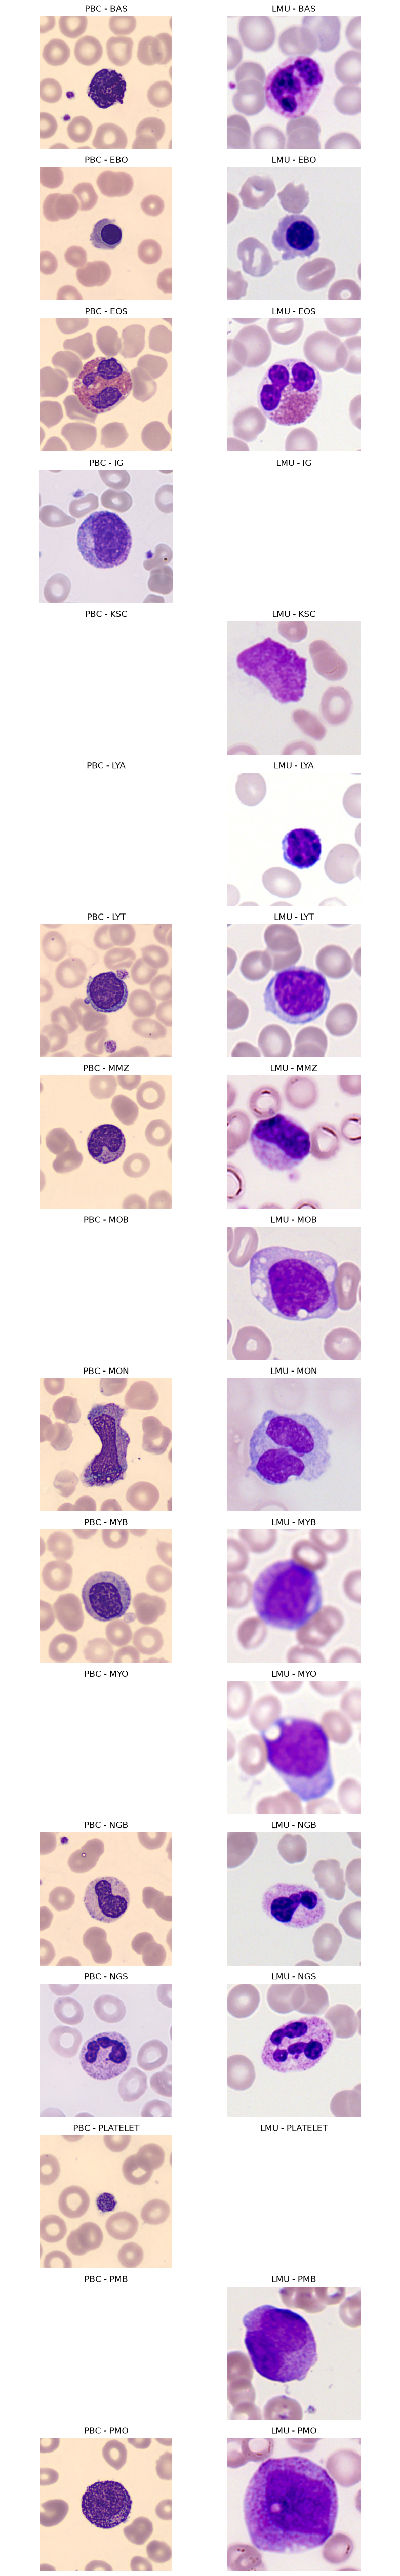

In [29]:

# Toutes les classes présentes dans au moins un dataset
classes = sorted(set(df_pkg_info["class_code"].dropna()) | set(df_pbc_info["class_code"].dropna()))

fig, axes = plt.subplots(len(classes),2,figsize=(8, 3 * len(classes)))

if len(classes) == 1:
    axes = [axes]

for i, cls in enumerate(classes):

    # PBC

    ax = axes[i][0]
    sample = df_pbc_info[df_pbc_info["class_code"] == cls]

    if len(sample):

        path = PBC / sample.iloc[0]["relative_path"]
        img = cv2.imread(str(path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)

    ax.set_title(f"PBC - {cls}")
    ax.axis("off")

    # LMU

    ax = axes[i][1]
    sample = df_pkg_info[df_pkg_info["class_code"] == cls]

    if len(sample):

        path = LMU / sample.iloc[0]["relative_path"]
        img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        # Gestion des TIFF RGBA
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA)
        ax.imshow(img)

    ax.set_title(f"LMU - {cls}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:


rows = []

for _, row in tqdm(df_all.iterrows(), total=len(df_all)):
    # Construction du chemin
    if row["source"] == "PBC_dataset_normal_DIB":
        img_path = PBC / row["relative_path"]
    else:
        img_path = LMU / row["relative_path"]

    # Lecture
    img = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)

    if img is None:
        continue

    # Suppression éventuelle de l'alpha
    if len(img.shape) == 3 and img.shape[2] == 4:
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)

    # Niveau de gris
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # CALCUL DES METRIQUES

    brightness = gray.mean()
    contrast = gray.std()
    sharpness = cv2.Laplacian(gray,cv2.CV_64F).var()

    rows.append({
        "brightness": brightness,
        "contrast": contrast,
        "sharpness": sharpness
    })

# Ajout au dataframe
df_metrics = pd.DataFrame(rows)

df_all = pd.concat(
    [df_all.reset_index(drop=True), df_metrics],
    axis=1
)

df_all.head()

  0%|          | 0/35457 [00:00<?, ?it/s]

,relative_path,class_code,re-annotation,re-re-annotation,width,height,channels,file_type,file_size,class_name,source,class_code_ori,class_name_ori,brightness,contrast,sharpness
0,BAS/BAS_0001.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU,NaN,NaN,186.536219,50.148466,14.844416
1,BAS/BAS_0002.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU,NaN,NaN,159.338831,85.110329,222.473679
2,BAS/BAS_0003.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU,NaN,NaN,211.228138,43.397897,19.861072
3,BAS/BAS_0004.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU,NaN,NaN,189.074675,55.505390,14.773192
4,BAS/BAS_0005.tiff,BAS,NaN,NaN,400,400,4,.tiff,640154,Basophil,PKG-AML-Cytomorphology_LMU,NaN,NaN,183.197369,57.654694,13.795417


In [31]:

def plot_histogram(df, column, bins=50, histnorm=None):
    """
    Affiche un histogramme superposé des deux datasets.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame contenant les données.

    column : str
        Colonne numérique à afficher.

    bins : int
        Nombre de classes de l'histogramme.

    histnorm : str | None
        None : nombre d'images
        "percent" : pourcentage
        "probability density" : densité
    """

    fig = px.histogram(
        df,
        x=column,
        color="source",
        barmode="overlay",
        opacity=0.6,
        nbins=bins,
        histnorm=histnorm,
        title=f"Distribution de '{column}' par source",
        labels={
            column: column.replace("_", " ").title(),
            "count": "Nombre d'images",
            "source": "Source"
        },
    )

    fig.update_layout(
        template="plotly_white",
        bargap=0.02,
        legend_title="Source",
        height=500
    )

    fig.show()

In [32]:
plot_histogram(df_all, "brightness",bins=50)

In [33]:
plot_histogram(df_all, "contrast",bins=50)

In [34]:
plot_histogram(df_all, "sharpness", bins=80)

In [35]:


cell_ratio = []
perimeter = []
circularity = []

for _, row in tqdm(df_all.iterrows(), total=len(df_all)):

    # -------------------------
    # Chargement image
    # -------------------------
    if row["source"] == "PBC_dataset_normal_DIB":
        img_path = PBC / row["relative_path"]
    else:
        img_path = LMU / row["relative_path"]

    img = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)

    if img is None:
        cell_ratio.append(np.nan)
        perimeter.append(np.nan)
        circularity.append(np.nan)
        continue

    # Suppression éventuelle du canal alpha
    if len(img.shape) == 3 and img.shape[2] == 4:
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)

    # -------------------------
    # Segmentation
    # -------------------------
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    _, mask = cv2.threshold(
        blur,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    kernel = np.ones((5,5), np.uint8)

    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        cell_ratio.append(np.nan)
        perimeter.append(np.nan)
        circularity.append(np.nan)
        continue

    largest = max(contours, key=cv2.contourArea)

    area = cv2.contourArea(largest)

    peri = cv2.arcLength(largest, True)

    ratio = area / (img.shape[0] * img.shape[1])

    if peri > 0:
        circ = (4 * np.pi * area) / (peri ** 2)
    else:
        circ = np.nan

    cell_ratio.append(ratio)
    perimeter.append(peri)
    circularity.append(circ)

# Ajout des colonnes
df_all["cell_ratio"] = cell_ratio
df_all["perimeter"] = perimeter
df_all["circularity"] = circularity

  0%|          | 0/35457 [00:00<?, ?it/s]

In [37]:
plot_histogram(df_all, "cell_ratio")

plot_histogram(df_all, "perimeter")

plot_histogram(df_all, "circularity")

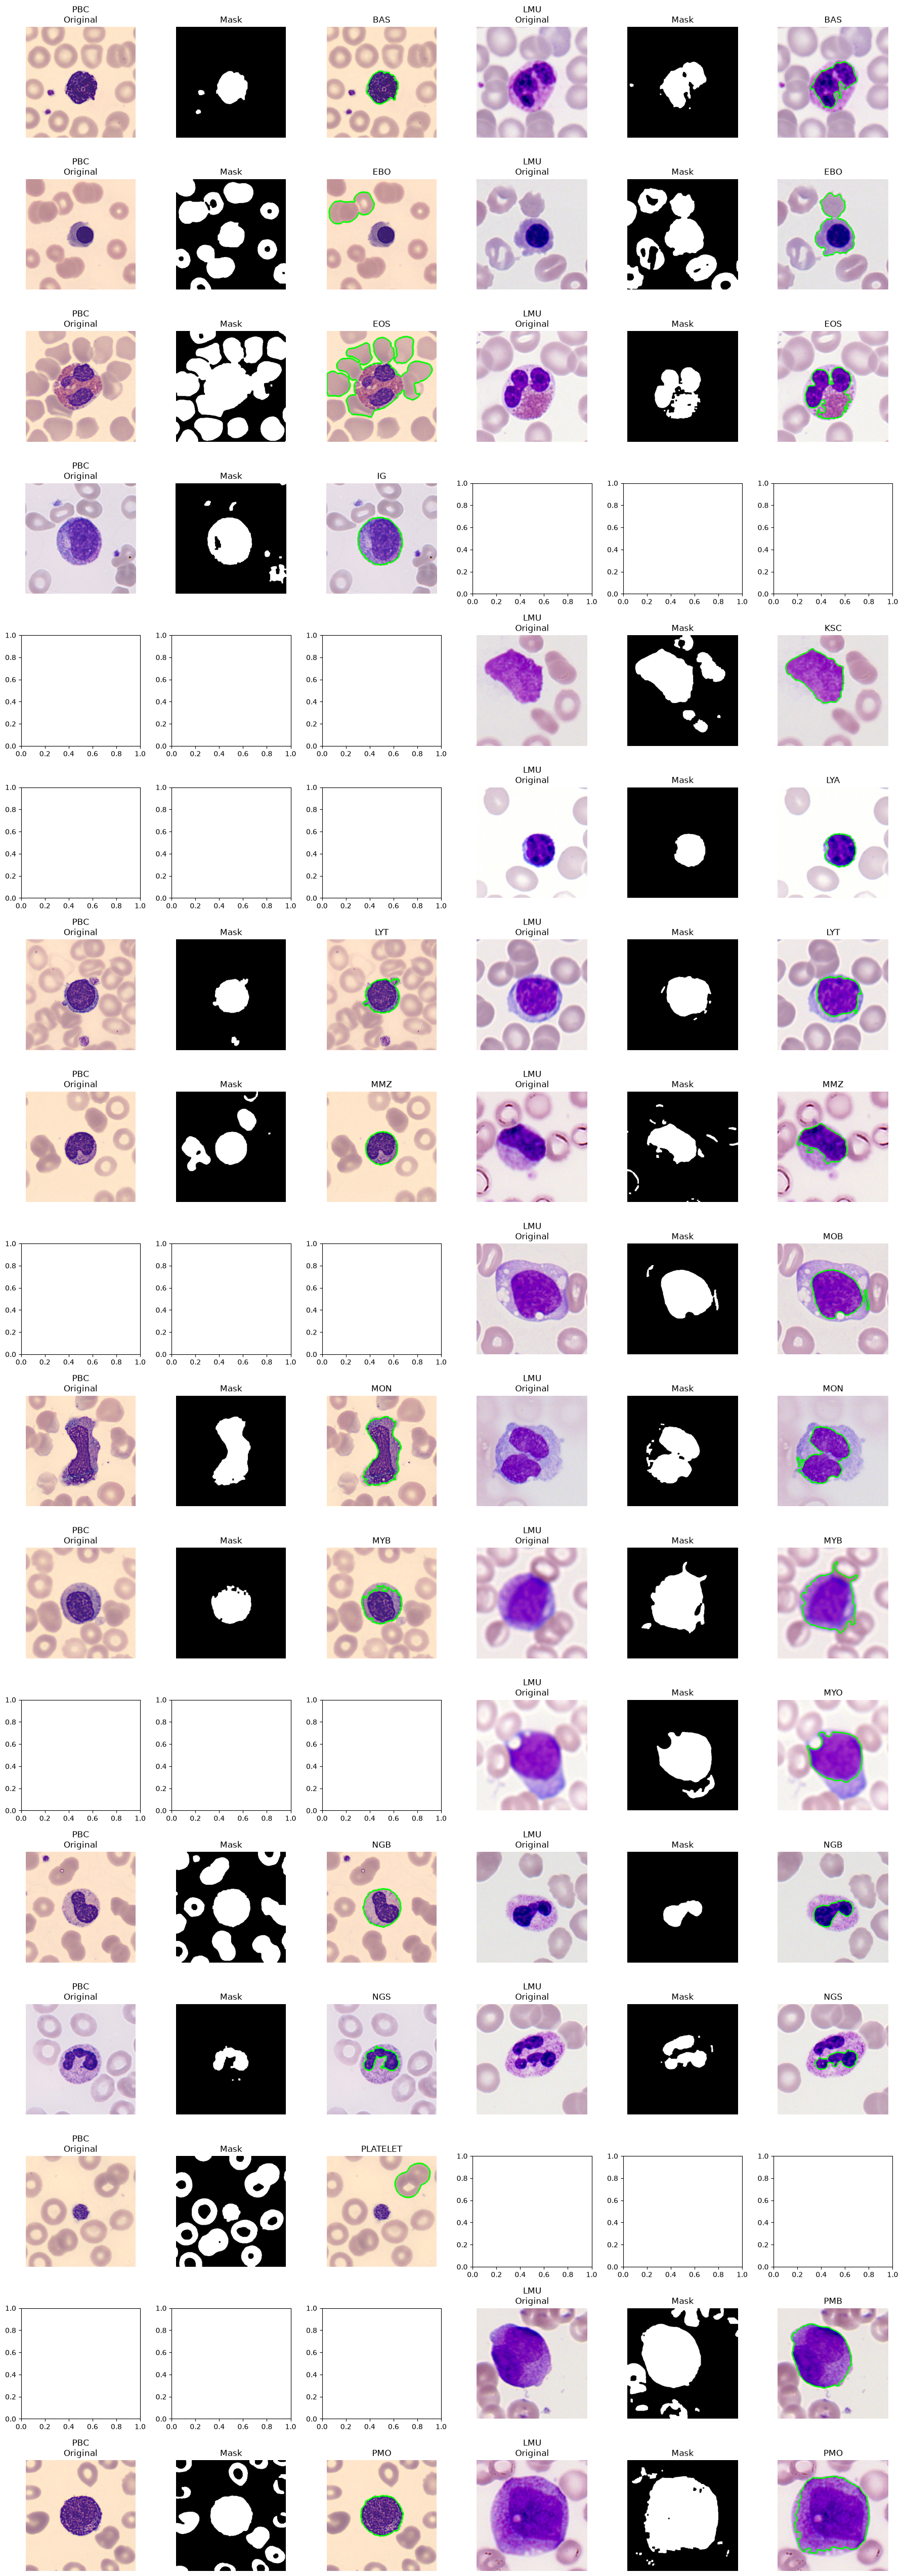

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Toutes les classes présentes dans au moins un dataset
classes = sorted(
    set(df_pkg_info["class_code"].dropna()) |
    set(df_pbc_info["class_code"].dropna())
)

# 6 colonnes :
# PBC : Original | Masque | Contour
# LMU : Original | Masque | Contour
fig, axes = plt.subplots(
    len(classes),
    6,
    figsize=(18, 3 * len(classes))
)

if len(classes) == 1:
    axes = np.array([axes])

datasets = [
    ("PBC", df_pbc_info, PBC),
    ("LMU", df_pkg_info, LMU),
]

for i, cls in enumerate(classes):

    for dataset_idx, (dataset_name, df, root) in enumerate(datasets):

        sample = df[df["class_code"] == cls]

        if sample.empty:
            continue

        path = root / sample.iloc[0]["relative_path"]

        img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

        if img is None:
            continue

        # Suppression éventuelle du canal alpha
        if len(img.shape) == 3 and img.shape[2] == 4:
            img = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)

        # ------------------------
        # Original
        # ------------------------

        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # ------------------------
        # Segmentation
        # ------------------------

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        blur = cv2.GaussianBlur(gray, (5, 5), 0)

        _, mask = cv2.threshold(
            blur,
            0,
            255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        kernel = np.ones((5, 5), np.uint8)

        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

        contours, _ = cv2.findContours(
            mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        debug = rgb.copy()

        if contours:

            largest = max(contours, key=cv2.contourArea)

            cv2.drawContours(
                debug,
                [largest],
                -1,
                (0, 255, 0),
                3
            )

        col = dataset_idx * 3

        # ------------------------
        # Original
        # ------------------------

        axes[i, col].imshow(rgb)
        axes[i, col].set_title(f"{dataset_name}\nOriginal")
        axes[i, col].axis("off")

        # ------------------------
        # Masque
        # ------------------------

        axes[i, col + 1].imshow(mask, cmap="gray")
        axes[i, col + 1].set_title("Mask")
        axes[i, col + 1].axis("off")

        # ------------------------
        # Contour
        # ------------------------

        axes[i, col + 2].imshow(debug)
        axes[i, col + 2].set_title(f"{cls}")
        axes[i, col + 2].axis("off")

plt.tight_layout()
plt.show()